# TrustSphere AI: results notebook

**Image-forgery detection with a trained EfficientNet-B0 on multi-quality error-level-analysis (ELA) maps, inside a multi-agent forensic pipeline.**

This notebook shows every result of the project: accuracy tables, confusion matrices, ROC and precision-recall curves, score distributions, per-fold accuracy,
the full-pipeline hold-out test, pixel-level localisation, the comparison with the base papers and a live run of the trained detector.

**How to run (VS Code):** open this file, click *Select Kernel* (top right) and choose a Python that has `numpy pandas matplotlib scikit-learn ipykernel`
(the last section also needs `torch timm pillow`), then click **Run All**. Save with `Ctrl+S`; the outputs are stored in the file, so it can be shown without running it.

Every number comes from **out-of-fold or held-out predictions**: no image is scored by a model that trained on it.
All files are read from `docs/evaluation/`, so the notebook works without the datasets and without a GPU. Only the last section runs a model.

## 1. Setup

In [1]:
%matplotlib inline
import json, os, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image as IPImage
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)

def find_root():
    p = Path.cwd().resolve()
    for d in [p, *p.parents]:
        if (d / "docs" / "evaluation" / "metrics.json").exists():
            return d
    raise FileNotFoundError("Open the notebook from inside the TrustSphere repository (docs/evaluation/metrics.json not found).")

ROOT = find_root()
EV, TR = ROOT / "docs" / "evaluation", ROOT / "docs" / "evaluation" / "training"
M = json.loads((EV / "metrics.json").read_text(encoding="utf-8"))

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold"})
BLUE, RED, GREEN, GREY = "#1f4e9c", "#c0392b", "#2e8b57", "#7f8c8d"
pct = lambda v, d=2: f"{v * 100:.{d}f}%"
print("repository folder:", ROOT.name)

repository folder: TrustSphere_Full_App


## 2. Experiments and how they are scored

| Experiment | What it tests |
|---|---|
| CASIA v2.0, random 5-fold | Standard stratified cross-validation (2,819 images) |
| CASIA v2.0, source-disjoint 5-fold | A tampered image is kept in the same fold as the authentic image it was made from, so the detector never sees a source in training and its forgery in testing |
| Columbia, whole image (ELA) | The CASIA-style detector on Columbia's uncompressed photographs (363 images) |
| Columbia, patch-based (SRM), random | 128-pixel patches on noise-residual (SRM) input; image score = mean of the top 5 % patch probabilities |
| Columbia, patch-based (SRM), scene-disjoint | Same, but every scene is kept inside one fold |

Class 1 = manipulated. Whole-image models use the probability 0.5 as the threshold; the patch-based models use a threshold chosen from the *other* folds' out-of-fold scores.

In [2]:
# (title, predictions file, score column, hard-prediction column or None, key in metrics.json)
EXPERIMENTS = [
    ("CASIA v2.0, random 5-fold",                        "oof_casia_v2_random.csv",            "p_fake", None,   "CASIA v2.0, random 5-fold"),
    ("CASIA v2.0, source-disjoint 5-fold",               "oof_casia_v2_group.csv",             "p_fake", None,   "CASIA v2.0, source-disjoint 5-fold"),
    ("Columbia, whole image (ELA)",                      "oof_columbia_random.csv",            "p_fake", None,   "Columbia, whole-image, ELA input"),
    ("Columbia, patch-based (SRM), random",              "oof_columbia_random_patch_srm.csv",  "score",  "pred", "Columbia, patch-based, SRM input"),
    ("Columbia, patch-based (SRM), scene-disjoint",      "oof_columbia_group_patch_srm.csv",   "score",  "pred", "Columbia, patch-based, SRM input, scene-disjoint"),
]

def eer_of(y, s):
    fpr, tpr, _ = roc_curve(y, s)
    i = int(np.nanargmin(np.abs((1 - tpr) - fpr)))
    return float((fpr[i] + 1 - tpr[i]) / 2), float(fpr[i]), float(tpr[i])

RES = {}
for title, fn, scol, pcol, mkey in EXPERIMENTS:
    d = pd.read_csv(TR / fn)
    y, s = d["label"].to_numpy(), d[scol].to_numpy()
    pred = d[pcol].to_numpy() if pcol else (s >= 0.5).astype(int)
    eer, ex, ey = eer_of(y, s)
    RES[title] = dict(y=y, s=s, pred=pred, mkey=mkey, eer=eer, eer_pt=(ex, ey),
                      acc=accuracy_score(y, pred), prec=precision_score(y, pred), rec=recall_score(y, pred), f1=f1_score(y, pred),
                      auc=roc_auc_score(y, s), ap=average_precision_score(y, s), cm=confusion_matrix(y, pred), n=len(y))
print({k: v["n"] for k, v in RES.items()})

{'CASIA v2.0, random 5-fold': 2819, 'CASIA v2.0, source-disjoint 5-fold': 2819, 'Columbia, whole image (ELA)': 363, 'Columbia, patch-based (SRM), random': 363, 'Columbia, patch-based (SRM), scene-disjoint': 363}


## 3. Summary of all experiments

,Experiment,Images,Accuracy,Precision,Recall,F1,ROC AUC,Avg. precision,EER,Matches saved metrics.json
0,"CASIA v2.0, random 5-fold",2819,95.53%,95.16%,95.01%,95.09%,0.9917,0.9889,4.58%,yes
1,"CASIA v2.0, source-disjoint 5-fold",2819,95.32%,95.28%,94.39%,94.83%,0.9933,0.9915,4.47%,yes
2,"Columbia, whole image (ELA)",363,87.60%,84.26%,92.22%,88.06%,0.9610,0.9573,11.85%,yes
3,"Columbia, patch-based (SRM), random",363,97.25%,96.70%,97.78%,97.24%,0.9872,0.9784,2.48%,yes
4,"Columbia, patch-based (SRM), scene-disjoint",363,96.97%,96.69%,97.22%,96.95%,0.9799,0.9694,2.76%,yes


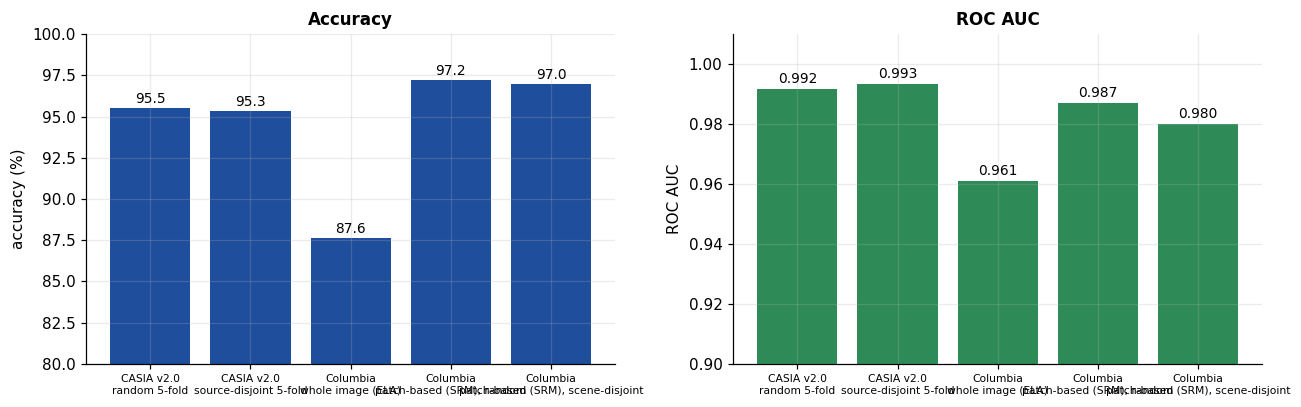

In [3]:
rows = []
for t, r in RES.items():
    saved = M[r["mkey"]]["pooled"]["accuracy"]
    rows.append({"Experiment": t, "Images": r["n"], "Accuracy": pct(r["acc"]), "Precision": pct(r["prec"]), "Recall": pct(r["rec"]),
                 "F1": pct(r["f1"]), "ROC AUC": f"{r['auc']:.4f}", "Avg. precision": f"{r['ap']:.4f}", "EER": pct(r["eer"]),
                 "Matches saved metrics.json": "yes" if abs(saved - r["acc"]) < 1e-3 else f"NO ({saved:.4f})"})
SUMMARY = pd.DataFrame(rows)
display(SUMMARY)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
names = [t.replace(", ", "\n", 1) for t in RES]
ax[0].bar(range(len(RES)), [r["acc"] * 100 for r in RES.values()], color=BLUE)
for i, r in enumerate(RES.values()):
    ax[0].text(i, r["acc"] * 100 + .3, f"{r['acc'] * 100:.1f}", ha="center", fontsize=9)
ax[0].set_ylim(80, 100); ax[0].set_xticks(range(len(RES))); ax[0].set_xticklabels(names, fontsize=7); ax[0].set_ylabel("accuracy (%)"); ax[0].set_title("Accuracy")
ax[1].bar(range(len(RES)), [r["auc"] for r in RES.values()], color=GREEN)
for i, r in enumerate(RES.values()):
    ax[1].text(i, r["auc"] + .002, f"{r['auc']:.3f}", ha="center", fontsize=9)
ax[1].set_ylim(.9, 1.01); ax[1].set_xticks(range(len(RES))); ax[1].set_xticklabels(names, fontsize=7); ax[1].set_ylabel("ROC AUC"); ax[1].set_title("ROC AUC")
plt.tight_layout(); plt.show()

## 4. Confusion matrix, ROC curve, precision-recall curve and score distribution for every experiment

*Confusion matrix:* rows = true class, columns = predicted class; each cell shows the count and the share of its row.
*ROC:* the dot marks the equal error rate (EER). *Score distribution:* the dashed line is the decision threshold.

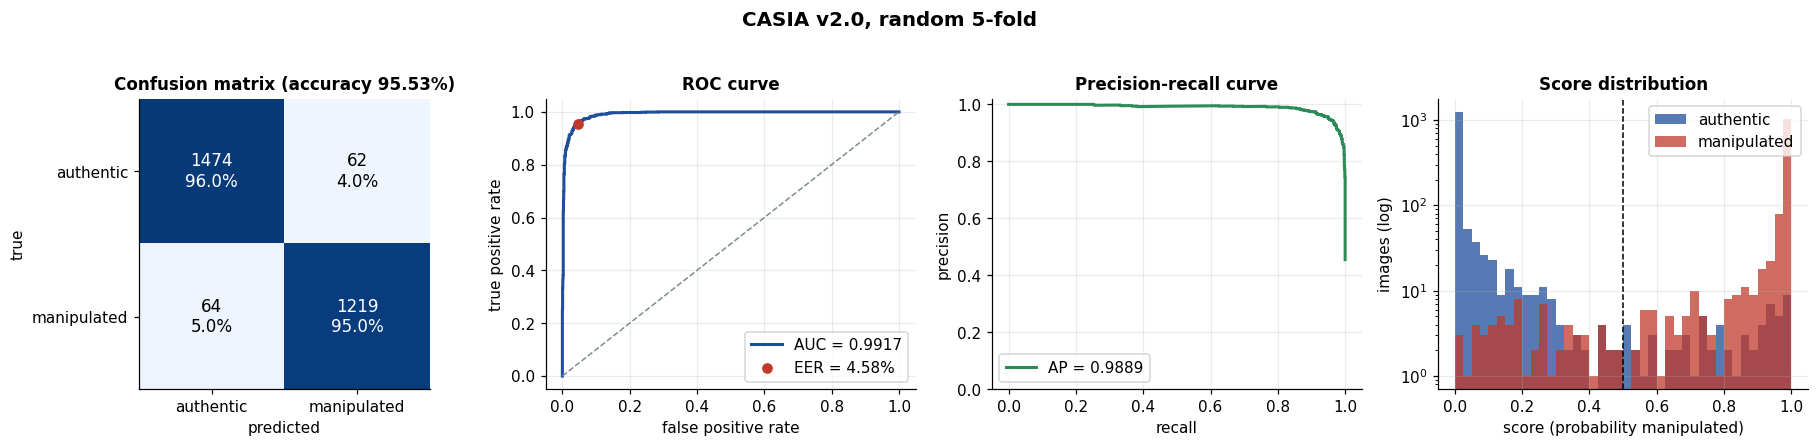

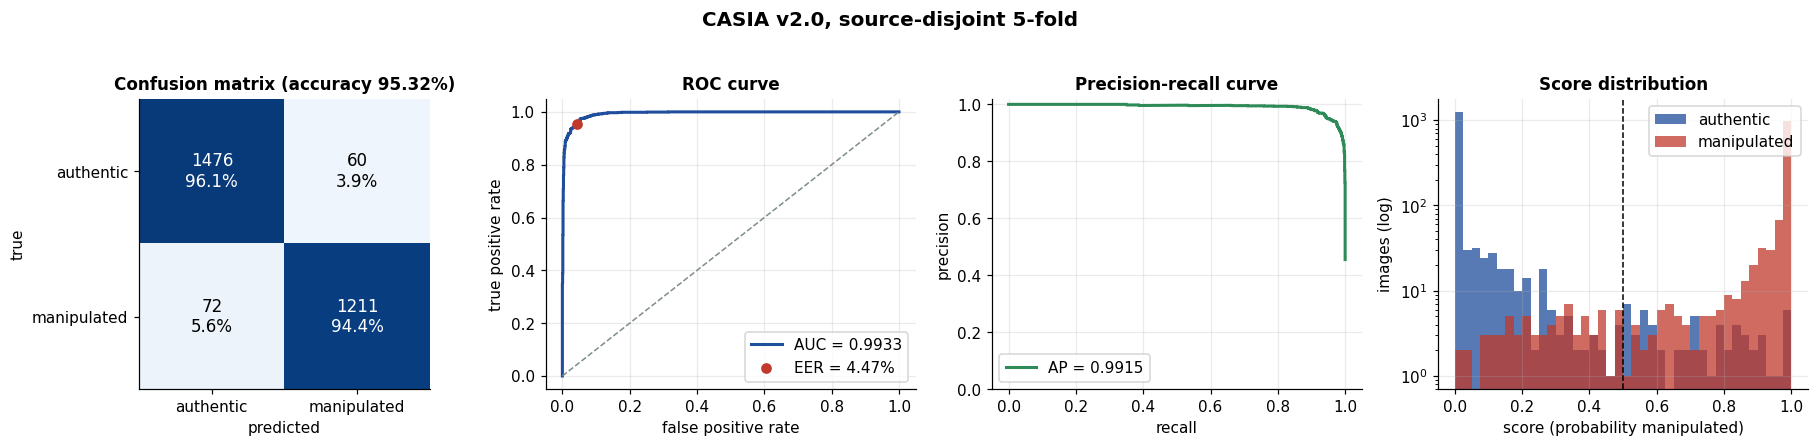

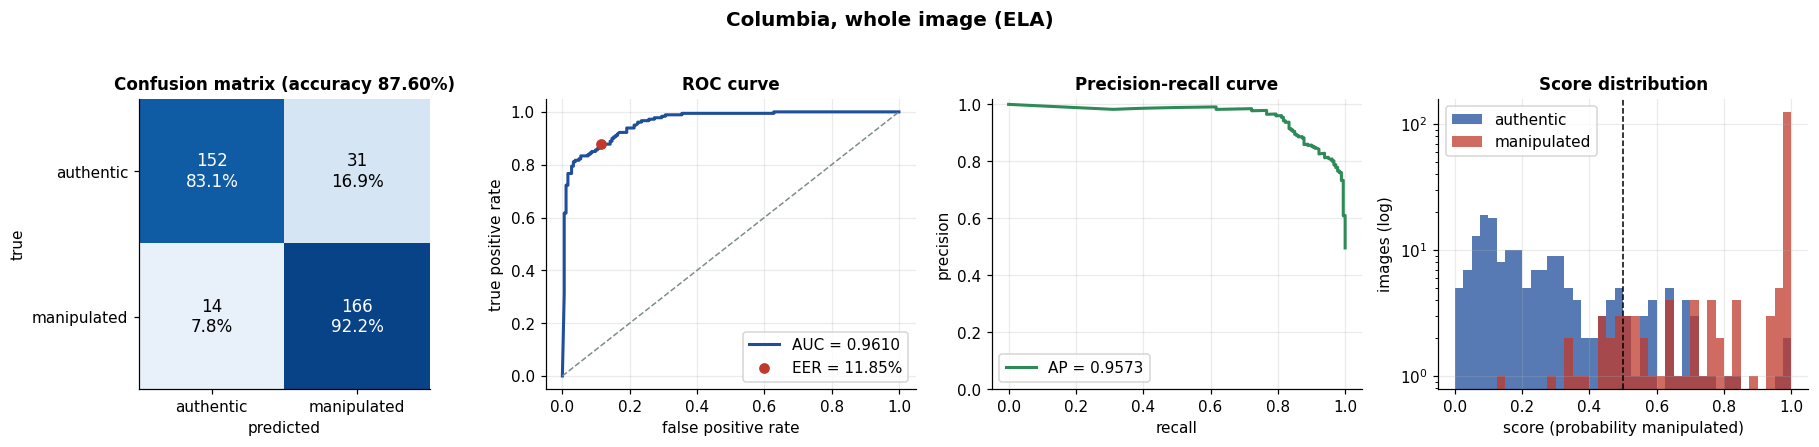

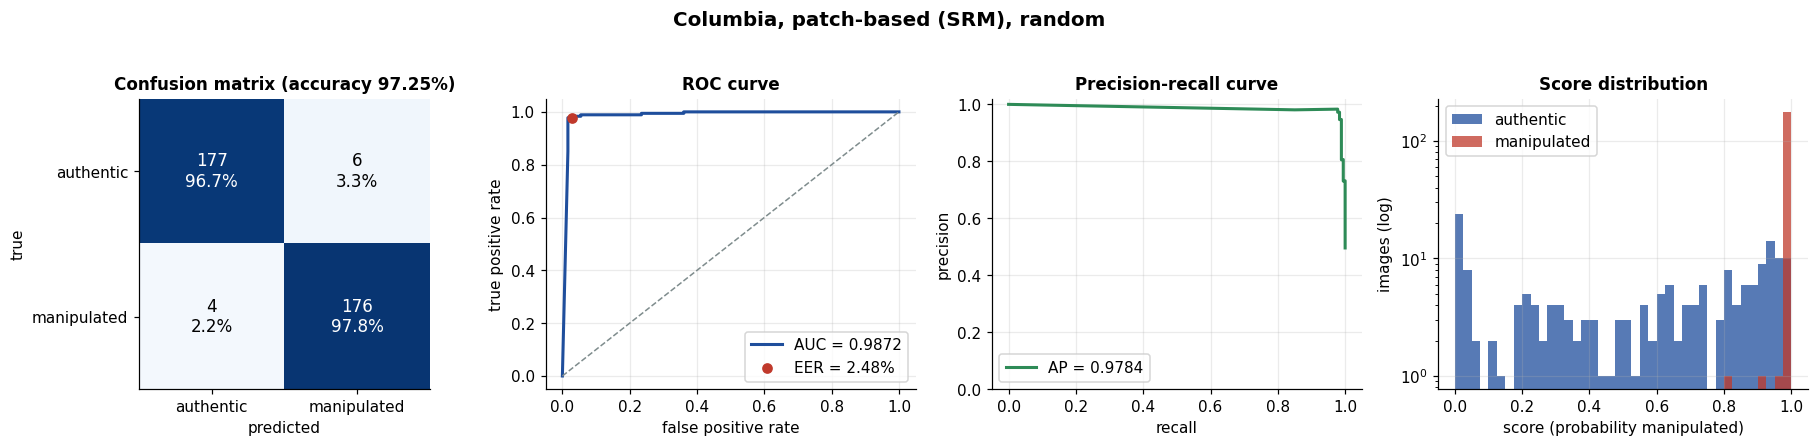

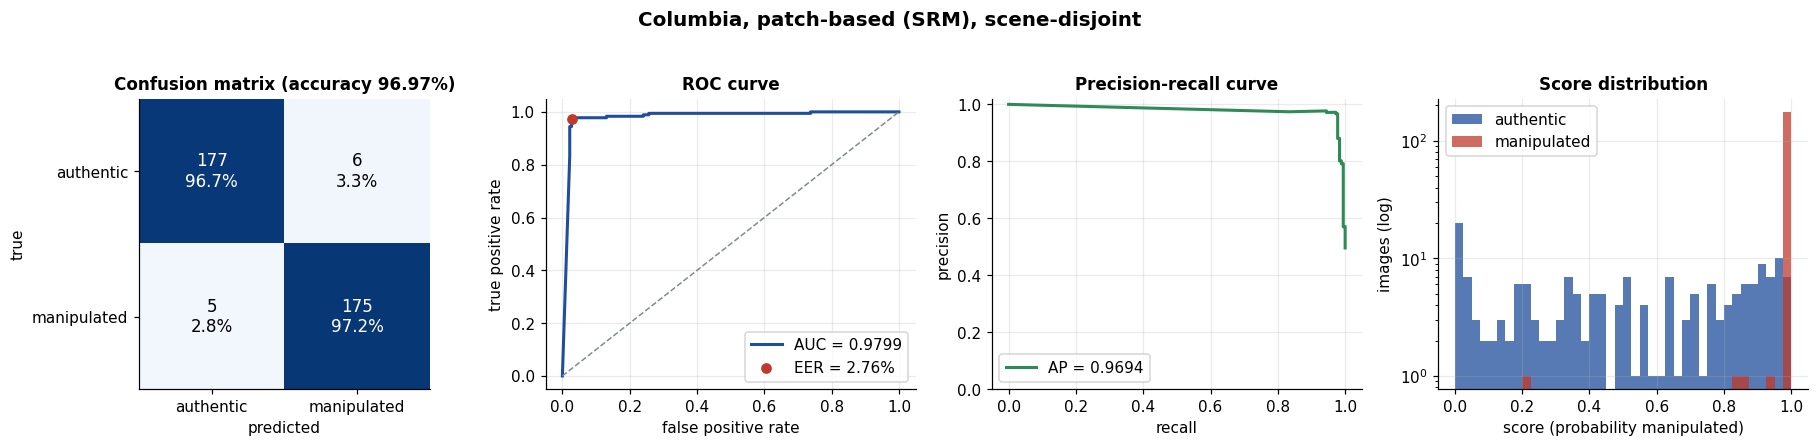

In [4]:
def plot_experiment(title, r):
    fig, ax = plt.subplots(1, 4, figsize=(17, 3.9))
    cm = r["cm"]; rowpct = cm / cm.sum(1, keepdims=True)
    ax[0].imshow(rowpct, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax[0].text(j, i, f"{cm[i, j]}\n{rowpct[i, j] * 100:.1f}%", ha="center", va="center", color="white" if rowpct[i, j] > .5 else "black", fontsize=11)
    ax[0].set_xticks([0, 1]); ax[0].set_yticks([0, 1]); ax[0].set_xticklabels(["authentic", "manipulated"]); ax[0].set_yticklabels(["authentic", "manipulated"])
    ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true"); ax[0].grid(False); ax[0].set_title(f"Confusion matrix (accuracy {r['acc'] * 100:.2f}%)")
    fpr, tpr, _ = roc_curve(r["y"], r["s"])
    ax[1].plot(fpr, tpr, color=BLUE, lw=2, label=f"AUC = {r['auc']:.4f}"); ax[1].plot([0, 1], [0, 1], "--", color=GREY, lw=1)
    ax[1].scatter(*r["eer_pt"], color=RED, zorder=3, label=f"EER = {r['eer'] * 100:.2f}%")
    ax[1].set_xlabel("false positive rate"); ax[1].set_ylabel("true positive rate"); ax[1].set_title("ROC curve"); ax[1].legend(loc="lower right")
    p, rc, _ = precision_recall_curve(r["y"], r["s"])
    ax[2].plot(rc, p, color=GREEN, lw=2, label=f"AP = {r['ap']:.4f}"); ax[2].set_xlabel("recall"); ax[2].set_ylabel("precision")
    ax[2].set_ylim(0, 1.02); ax[2].set_title("Precision-recall curve"); ax[2].legend(loc="lower left")
    s0, s1 = r["s"][r["y"] == 0], r["s"][r["y"] == 1]
    bins = np.linspace(0, 1, 41)
    ax[3].hist(s0, bins, color=BLUE, alpha=.75, label="authentic"); ax[3].hist(s1, bins, color=RED, alpha=.75, label="manipulated")
    ax[3].set_yscale("log"); ax[3].set_xlabel("score (probability manipulated)"); ax[3].set_ylabel("images (log)"); ax[3].set_title("Score distribution"); ax[3].legend()
    thr = 0.5 if r["mkey"].startswith(("CASIA", "Columbia, whole")) else None
    if thr is not None:
        ax[3].axvline(thr, ls="--", color="black", lw=1)
    fig.suptitle(title, fontsize=13, fontweight="bold", y=1.03)
    plt.tight_layout(); plt.show()

for t, r in RES.items():
    plot_experiment(t, r)

## 5. Accuracy of each cross-validation fold

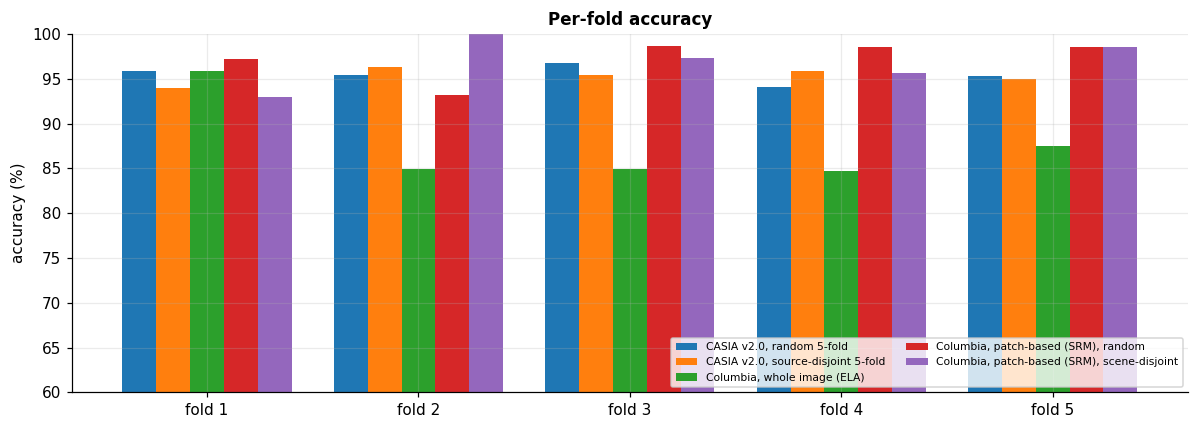

,Experiment,Mean of folds,Std,Folds (%)
0,"CASIA v2.0, random 5-fold",95.53%,0.86,"95.9, 95.4, 96.8, 94.2, 95.4"
1,"CASIA v2.0, source-disjoint 5-fold",95.32%,0.80,"94.0, 96.3, 95.4, 95.9, 95.0"
2,"Columbia, whole image (ELA)",87.60%,4.27,"95.9, 84.9, 84.9, 84.7, 87.5"
3,"Columbia, patch-based (SRM), random",97.25%,2.12,"97.3, 93.2, 98.6, 98.6, 98.6"
4,"Columbia, patch-based (SRM), scene-disjoint",96.92%,2.43,"93.0, 100.0, 97.4, 95.7, 98.6"


In [5]:
fig, ax = plt.subplots(figsize=(11, 4))
w = 0.16
for k, (t, r) in enumerate(RES.items()):
    folds = [f if isinstance(f, (int, float)) else f["accuracy"] for f in M[r["mkey"]]["folds"]]
    ax.bar(np.arange(len(folds)) + (k - 2) * w, np.array(folds) * 100, w, label=t)
ax.set_xticks(range(5)); ax.set_xticklabels([f"fold {i + 1}" for i in range(5)]); ax.set_ylim(60, 100); ax.set_ylabel("accuracy (%)")
ax.set_title("Per-fold accuracy"); ax.legend(fontsize=7, ncol=2, loc="lower right"); plt.tight_layout(); plt.show()

fold_rows = []
for t, r in RES.items():
    m = M[r["mkey"]]
    fold_rows.append({"Experiment": t, "Mean of folds": pct(m["mean_fold_accuracy"]), "Std": f"{m['std_fold_accuracy'] * 100:.2f}",
                      "Folds (%)": ", ".join(f"{(f if isinstance(f, (int, float)) else f['accuracy']) * 100:.1f}" for f in m["folds"])})
display(pd.DataFrame(fold_rows))

## 6. The full pipeline on held-out images

588 CASIA v2.0 images (301 authentic, 287 tampered) that the detector never saw: an 80/20 split that keeps every tampered image with its source.
The **real agents** (metadata, image forensics with the trained detector, provenance) and the **decision engine** ran on every file.
Verdict bands: *Authentic* at or above 0.75, *Fake* at or below 0.40, otherwise *Inconclusive* (sent to human review).

engine verdict,Authentic,Inconclusive,Fake
true,,,
authentic,251,42,8
tampered,3,14,270


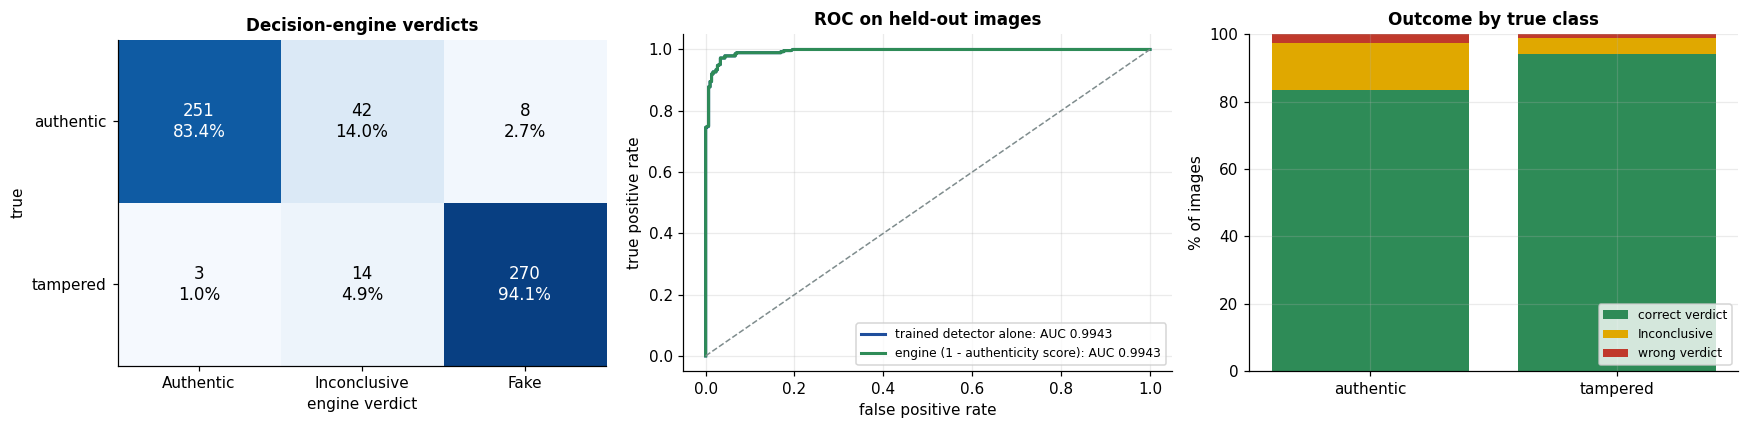

,Measure,Value
0,Images,588
1,Decided by the engine (not Inconclusive),90.48%
2,Accuracy on decided images,97.93%
3,Strict accuracy (Inconclusive counted wrong),88.61%
4,Authentic images called Fake,2.66%
5,Tampered images called Authentic,1.05%
6,Forced two-way call (below 0.5 = Fake): accura...,96.43% / 0.9943 / 3.05%
7,Detector alone: accuracy / AUC / EER,96.26% / 0.9943 / 3.05%


In [6]:
P = pd.read_csv(EV / "predictions.csv")
H = M["pipeline_holdout"]
order = ["Authentic", "Inconclusive", "Fake"]
truth = np.where(P["label"] == 1, "tampered", "authentic")
ct = pd.crosstab(pd.Series(truth, name="true"), P["verdict"].rename("engine verdict")).reindex(index=["authentic", "tampered"], columns=order, fill_value=0)
display(ct)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
rp = ct.to_numpy() / ct.to_numpy().sum(1, keepdims=True)
ax[0].imshow(rp, cmap="Blues", vmin=0, vmax=1)
for i in range(2):
    for j in range(3):
        ax[0].text(j, i, f"{ct.to_numpy()[i, j]}\n{rp[i, j] * 100:.1f}%", ha="center", va="center", color="white" if rp[i, j] > .5 else "black", fontsize=11)
ax[0].set_xticks(range(3)); ax[0].set_xticklabels(order); ax[0].set_yticks(range(2)); ax[0].set_yticklabels(ct.index); ax[0].grid(False)
ax[0].set_xlabel("engine verdict"); ax[0].set_ylabel("true"); ax[0].set_title("Decision-engine verdicts")

y = P["label"].to_numpy()
for lab, sc, col in (("trained detector alone", P["p_manipulated"].to_numpy(), BLUE), ("engine (1 - authenticity score)", 1 - P["score"].to_numpy(), GREEN)):
    f, t, _ = roc_curve(y, sc); ax[1].plot(f, t, color=col, lw=2, label=f"{lab}: AUC {roc_auc_score(y, sc):.4f}")
ax[1].plot([0, 1], [0, 1], "--", color=GREY, lw=1); ax[1].set_xlabel("false positive rate"); ax[1].set_ylabel("true positive rate"); ax[1].set_title("ROC on held-out images"); ax[1].legend(loc="lower right", fontsize=8)

bs = H["by_subset"]
labels = ["authentic", "tampered"]
vals = {"correct verdict": [v["correct"] for v in bs.values()], "Inconclusive": [v["inconclusive"] for v in bs.values()], "wrong verdict": [v["wrong"] for v in bs.values()]}
bottom = np.zeros(2)
for (k, v), c in zip(vals.items(), (GREEN, "#e0a800", RED)):
    ax[2].bar(labels, np.array(v) * 100, bottom=bottom * 100, color=c, label=k); bottom += np.array(v)
ax[2].set_ylabel("% of images"); ax[2].set_title("Outcome by true class"); ax[2].legend(fontsize=8, loc="lower right"); ax[2].set_ylim(0, 100)
plt.tight_layout(); plt.show()

rows = [["Images", H["n"]], ["Decided by the engine (not Inconclusive)", pct(H["coverage_decided"])], ["Accuracy on decided images", pct(H["accuracy_on_decided"])],
        ["Strict accuracy (Inconclusive counted wrong)", pct(H["accuracy_strict"])], ["Authentic images called Fake", pct(H["false_positive_rate"])],
        ["Tampered images called Authentic", pct(H["false_negative_rate"])]]
f2, d1 = H["forced_two_way"], H["detector_alone"]
rows += [["Forced two-way call (below 0.5 = Fake): accuracy / AUC / EER", f"{pct(f2['accuracy'])} / {f2['roc_auc']:.4f} / {pct(f2['eer'])}"],
         ["Detector alone: accuracy / AUC / EER", f"{pct(d1['accuracy'])} / {d1['roc_auc']:.4f} / {pct(d1['eer'])}"]]
display(pd.DataFrame(rows, columns=["Measure", "Value"]))

## 7. Pixel-level localisation (a limitation)

In [7]:
L = M["localizer"]
a, b, g = L["casia_validation"], L["columbia"], L["gift_reported"]
display(Markdown(f"A U-Net-style network (EfficientNet-B0 encoder, RGB + ELA input) trained on CASIA v2.0 only; Columbia was never used in training. Protocol: {L['protocol']}."))
display(pd.DataFrame([
    ["CASIA v2.0 validation (held out)", f"{a['pixel_f1_pooled']:.4f}", f"{a['pixel_f1_mean_per_image']:.4f}", f"{a['pixel_auc']:.4f}", f"{a['image_auc_from_map']:.4f}"],
    ["Columbia (cross-dataset)",           f"{b['pixel_f1_pooled']:.4f}", f"{b['pixel_f1_mean_per_image']:.4f}", f"{b['pixel_auc']:.4f}", f"{b['image_auc_from_map']:.4f}"]],
    columns=["Test set", "Pooled pixel F1", "Mean per-image F1", "Pixel AUC", "Image AUC from the map"]))
print("GIFT (Chen et al. 2026) reports on Columbia:", g)
display(Markdown("**Honest reading:** the localiser works on CASIA-like images but does **not** reach the published Columbia F1 of about 0.65. "
                 "The verdict does not depend on localisation, so heatmaps are supporting evidence only."))

A U-Net-style network (EfficientNet-B0 encoder, RGB + ELA input) trained on CASIA v2.0 only; Columbia was never used in training. Protocol: train on CASIA v2.0, test on Columbia (as GIFT, Chen et al. 2026).

,Test set,Pooled pixel F1,Mean per-image F1,Pixel AUC,Image AUC from the map
0,CASIA v2.0 validation (held out),0.8889,0.7554,0.9569,0.9868
1,Columbia (cross-dataset),0.4330,0.3885,0.6743,0.7994


GIFT (Chen et al. 2026) reports on Columbia: {'columbia_f1': {'GIFT': 0.6497, 'E-GIFT': 0.6558, 'MFCN': 0.604, 'Edge-enhanced MFCN': 0.6117, 'SFCN': 0.582}, 'casia_v1_f1': {'GIFT': 0.5728, 'E-GIFT': 0.621}, 'casia_v1_auc': {'GIFT': 0.888, 'E-GIFT': 0.883, 'EVP': 0.862}}


**Honest reading:** the localiser works on CASIA-like images but does **not** reach the published Columbia F1 of about 0.65. The verdict does not depend on localisation, so heatmaps are supporting evidence only.

## 8. Comparison with the base papers

Only results that the detector exceeds on a comparable dataset and metric are listed. The papers use different splits and training sets, so this is context, not a leaderboard.
The full comparison, including results the detector does not reach, is in `docs/evaluation/EVALUATION.md`.

,Source,Dataset,Metric,Reported,TrustSphere (random / source- or scene-disjoint)
0,"[2] Ravula and Singh, 2025 (GAN-ViT-CMFD)",CASIA v2.0,accuracy,94.4%,95.53% / 95.32%
1,"[3] Rehman and Jain, 2025 (CNN + SVM)",CASIA v2.0,mean accuracy over folds,93.39% (best single figure 98.91%),95.53% / 95.32%
2,"[4] Deb and Kar, 2026 (Satyachitra)",CASIA v2.0,precision / recall / F1,87.31 / 90.15 / 88.33,95.16 / 95.01 / 95.09
3,Earlier Columbia methods listed in [1],Columbia,accuracy,91% to 93.4%,97.25% / 96.97% (patch-based)


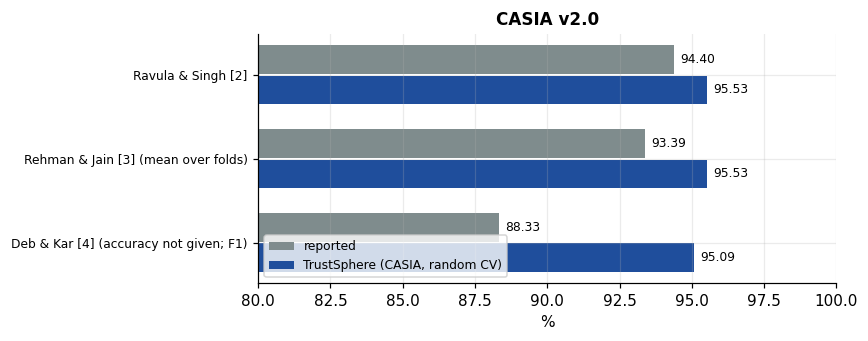

In [8]:
cr, cg = RES["CASIA v2.0, random 5-fold"], RES["CASIA v2.0, source-disjoint 5-fold"]
cp, cs = RES["Columbia, patch-based (SRM), random"], RES["Columbia, patch-based (SRM), scene-disjoint"]
comp = pd.DataFrame([
    ["[2] Ravula and Singh, 2025 (GAN-ViT-CMFD)", "CASIA v2.0", "accuracy", "94.4%", f"{pct(cr['acc'])} / {pct(cg['acc'])}"],
    ["[3] Rehman and Jain, 2025 (CNN + SVM)",     "CASIA v2.0", "mean accuracy over folds", "93.39% (best single figure 98.91%)", f"{pct(cr['acc'])} / {pct(cg['acc'])}"],
    ["[4] Deb and Kar, 2026 (Satyachitra)",       "CASIA v2.0", "precision / recall / F1", "87.31 / 90.15 / 88.33", f"{cr['prec'] * 100:.2f} / {cr['rec'] * 100:.2f} / {cr['f1'] * 100:.2f}"],
    ["Earlier Columbia methods listed in [1]",    "Columbia",   "accuracy", "91% to 93.4%", f"{pct(cp['acc'])} / {pct(cs['acc'])} (patch-based)"],
], columns=["Source", "Dataset", "Metric", "Reported", "TrustSphere (random / source- or scene-disjoint)"])
display(comp)

fig, ax = plt.subplots(figsize=(8, 3.2))
items = [("Deb & Kar [4] (accuracy not given; F1)", 88.33, cr["f1"] * 100), ("Rehman & Jain [3] (mean over folds)", 93.39, cr["acc"] * 100), ("Ravula & Singh [2]", 94.4, cr["acc"] * 100)]
for i, (n, rep, ours) in enumerate(items):
    ax.barh(i + .18, rep, .34, color=GREY, label="reported" if i == 0 else None); ax.barh(i - .18, ours, .34, color=BLUE, label="TrustSphere (CASIA, random CV)" if i == 0 else None)
    ax.text(rep + .2, i + .18, f"{rep:.2f}", va="center", fontsize=8); ax.text(ours + .2, i - .18, f"{ours:.2f}", va="center", fontsize=8)
ax.set_yticks(range(len(items))); ax.set_yticklabels([n for n, *_ in items], fontsize=8); ax.set_xlim(80, 100); ax.set_xlabel("%"); ax.legend(fontsize=8, loc="lower left"); ax.set_title("CASIA v2.0")
plt.tight_layout(); plt.show()

## 9. Sample outputs of the pipeline

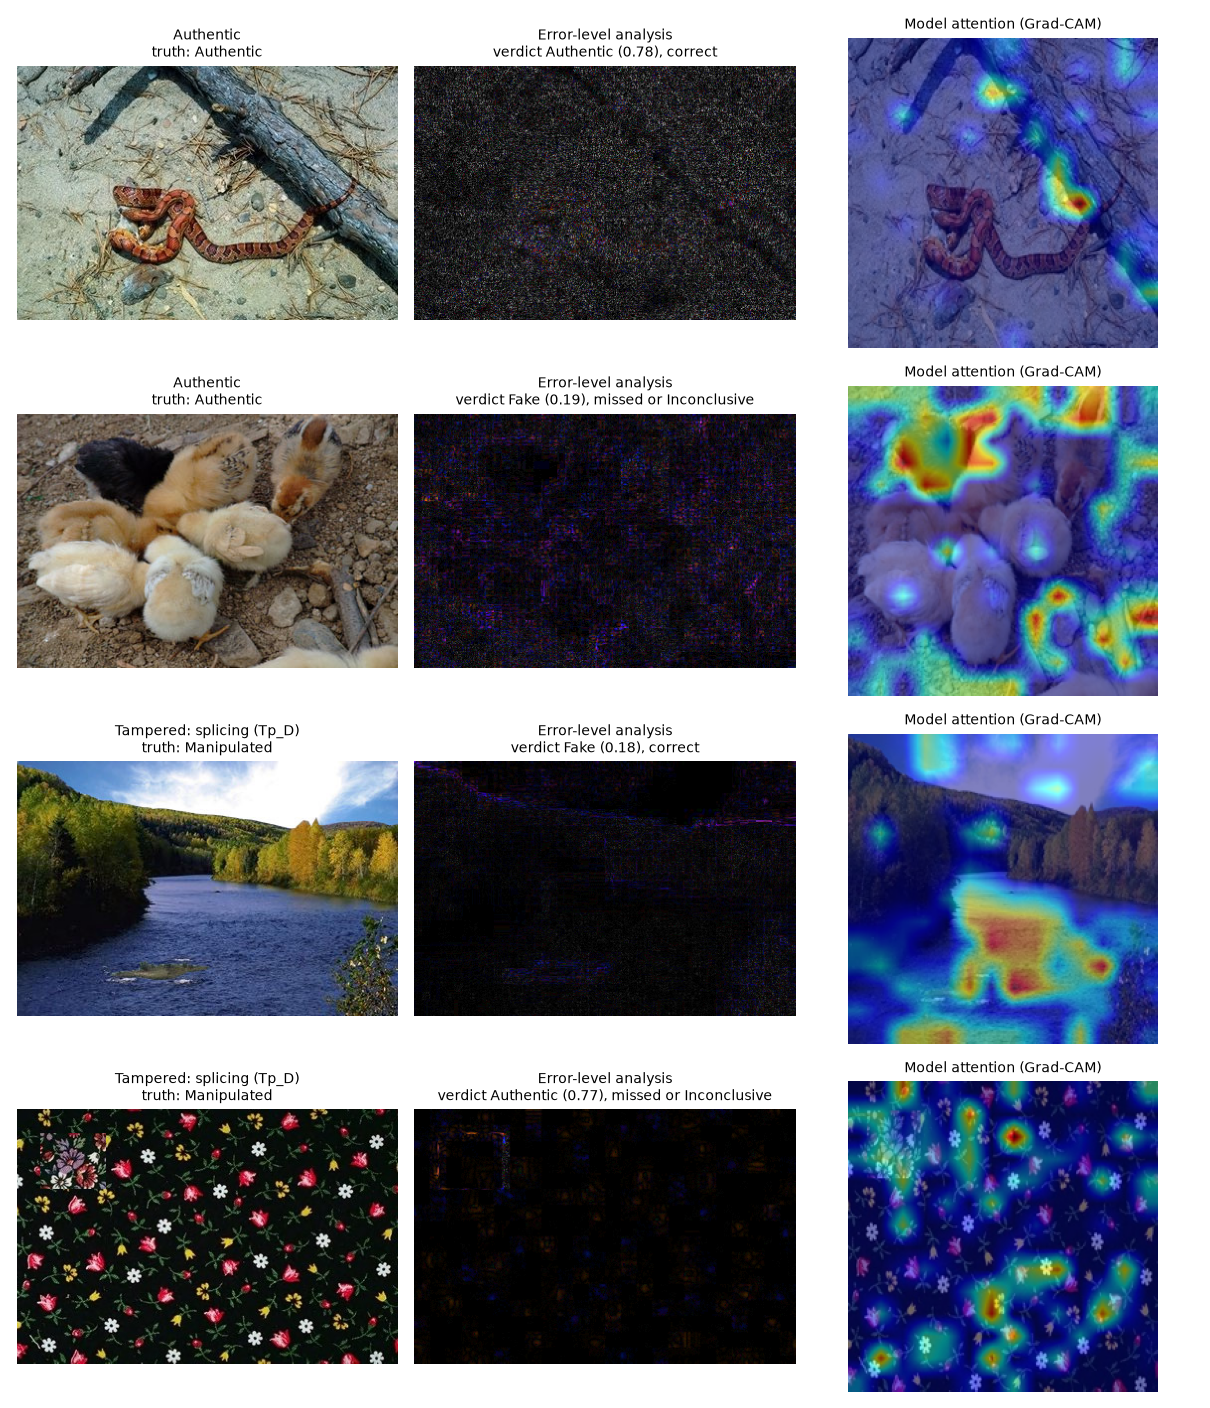

Au_ani_00050.jpg.png  (truth: Authentic, outcome: correct)
   verdict: Authentic | authenticity score: 0.78 | manipulation type: None
Au_ani_10116.jpg.png  (truth: Authentic, outcome: missed or Inconclusive)
   verdict: Fake | authenticity score: 0.1925 | manipulation type: Image Splicing / Tampering


In [9]:
display(IPImage(filename=str(EV / "pipeline_samples.png")))
smp = sorted((EV / "samples").glob("*.json"))
for f in smp[:2]:
    j = json.loads(f.read_text(encoding="utf-8"))
    dec = j.get("decision", {})
    print(f"{j['file']}  (truth: {j['truth']}, outcome: {j['outcome']})")
    print("   verdict:", dec.get("verdict"), "| authenticity score:", dec.get("overall_score"), "| manipulation type:", dec.get("manipulation_type"))

## 10. Live demo: run the trained detector on held-out images

The detector below is `casia_v2_group_holdout.pt`, trained on 80 % of CASIA v2.0. The six images shown were drawn at random from the other 20 %, so the model has **never seen them**.
Columns: the image, its multi-quality ELA map (the detector's input: JPEG qualities 70, 85, 95 as the R, G, B channels), the ground-truth mask (tampered images) and the prediction.
To test your own image, set `MY_IMAGE` in the next cell.

detector loaded: True | {'file': 'casia_v2_group_holdout.pt', 'name': 'EfficientNet-B0 on multi-quality ELA (trained on 80% of CASIA v2.0)', 'input': 'multiq', 'channels': 3}


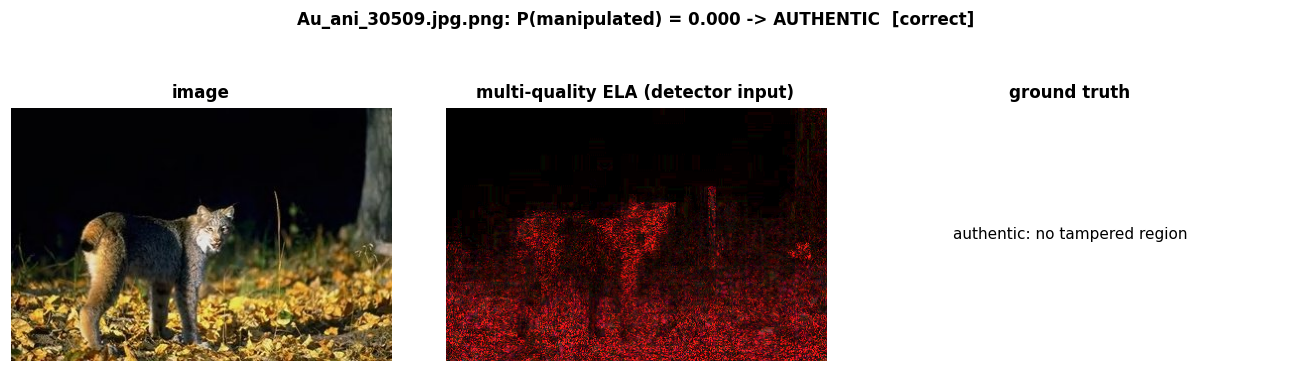

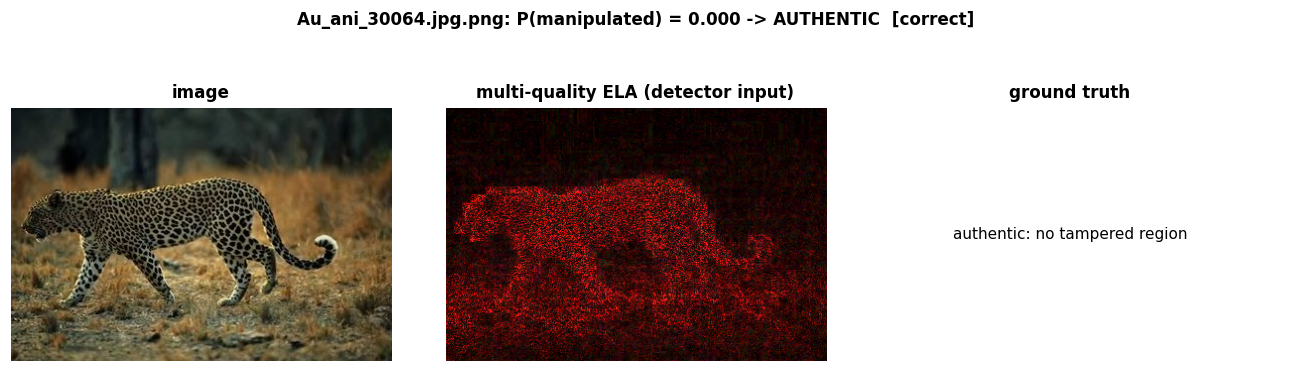

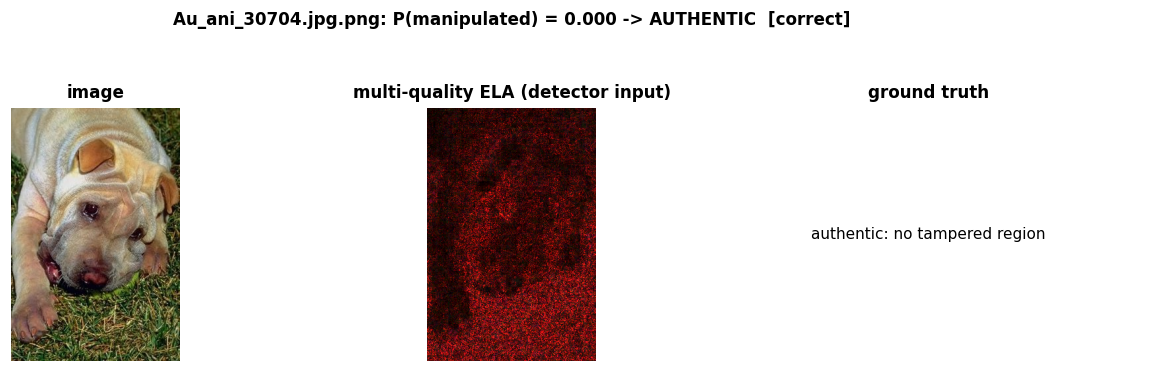

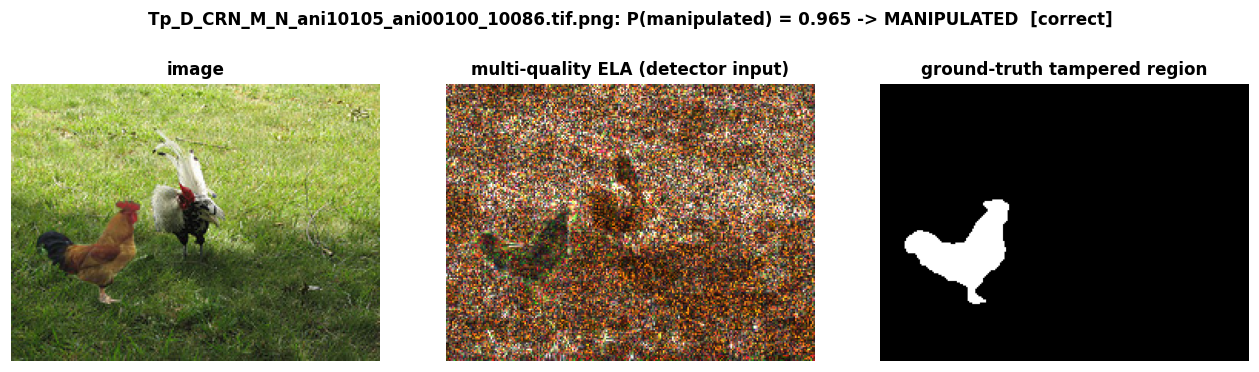

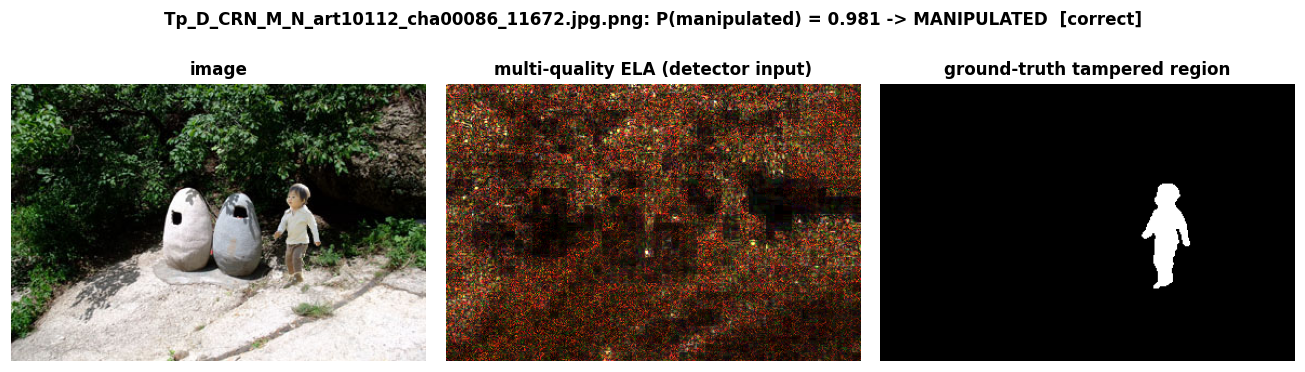

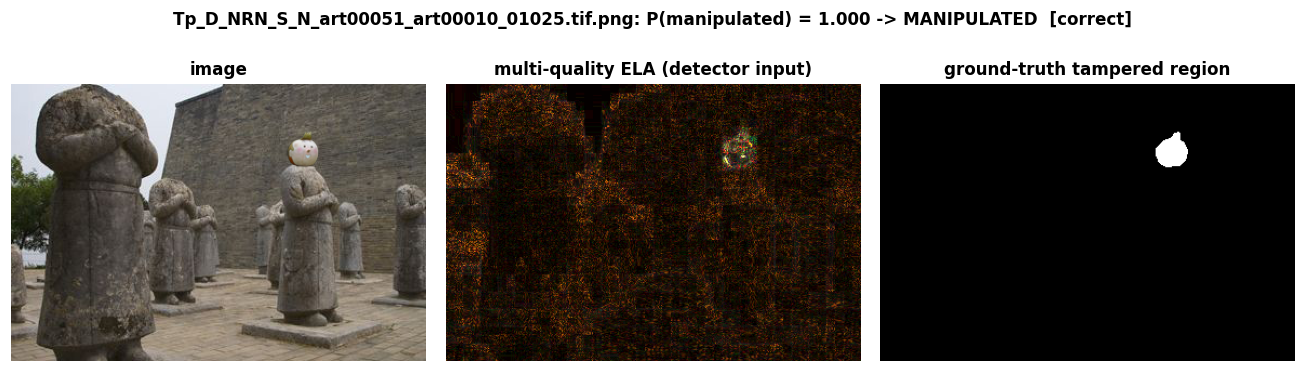

,image,truth,P(manipulated),prediction
0,Au_ani_30509.jpg.png,authentic,0.0000,authentic
1,Au_ani_30064.jpg.png,authentic,0.0000,authentic
2,Au_ani_30704.jpg.png,authentic,0.0000,authentic
3,Tp_D_CRN_M_N_ani10105_ani00100_10086.tif.png,tampered,0.9649,manipulated
4,Tp_D_CRN_M_N_art10112_cha00086_11672.jpg.png,tampered,0.9813,manipulated
5,Tp_D_NRN_S_N_art00051_art00010_01025.tif.png,tampered,1.0000,manipulated


correct on 6 of 6 random held-out images


In [10]:
import tempfile
from PIL import Image, ImageChops
import io

DEMO = EV / "demo_images"
tmp = Path(tempfile.mkdtemp()) / "manifest.json"
tmp.write_text(json.dumps({"detectors": [{"file": "casia_v2_group_holdout.pt", "name": "EfficientNet-B0 on multi-quality ELA (trained on 80% of CASIA v2.0)"}]}), encoding="utf-8")
os.environ["TRUSTSPHERE_DETECTOR_MANIFEST"] = str(tmp)
sys.path.insert(0, str(ROOT / "backend"))
try:
    from core import trained_detector as td
    DETECTOR_OK = td.available()
    print("detector loaded:", DETECTOR_OK, "|", td.info() if DETECTOR_OK else td._state["error"])
except Exception as exc:
    DETECTOR_OK = False
    print("detector not available here (needs torch and timm):", exc)

def ela_rgb(path):
    img = Image.open(path).convert("RGB"); ch = []
    for q in (70, 85, 95):
        buf = io.BytesIO(); img.save(buf, "JPEG", quality=q); buf.seek(0)
        d = np.asarray(ImageChops.difference(img, Image.open(buf).convert("RGB")), dtype=np.float32).mean(2) * 14
        ch.append(np.clip(d, 0, 255).astype(np.uint8))
    return np.stack(ch, 2)

def show(path, truth=None, mask=None):
    img = Image.open(path).convert("RGB")
    out = td.predict(str(path)) if DETECTOR_OK else None
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
    ax[0].imshow(img); ax[0].set_title("image"); ax[1].imshow(ela_rgb(path)); ax[1].set_title("multi-quality ELA (detector input)")
    if mask is not None and Path(mask).exists():
        ax[2].imshow(Image.open(mask).convert("L"), cmap="gray"); ax[2].set_title("ground-truth tampered region")
    else:
        ax[2].text(.5, .5, "no mask" if truth != 0 else "authentic: no tampered region", ha="center", va="center"); ax[2].set_title("ground truth")
    for a in ax: a.axis("off")
    if out:
        verdict = "MANIPULATED" if out["p_fake"] >= .5 else "AUTHENTIC"
        ok = "" if truth is None else ("  [correct]" if (out["p_fake"] >= .5) == bool(truth) else "  [WRONG]")
        fig.suptitle(f"{Path(path).name}: P(manipulated) = {out['p_fake']:.3f} -> {verdict}{ok}", fontsize=11, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.92]); plt.show()
    return out["p_fake"] if out else None

demo = json.loads((DEMO / "demo_images.json").read_text(encoding="utf-8"))
results = []
for d in demo:
    name = d["file"]
    p = show(DEMO / name, d["label"], DEMO / name.replace(".png", ".mask.png"))
    results.append({"image": name, "truth": "tampered" if d["label"] else "authentic", "P(manipulated)": None if p is None else round(p, 4),
                    "prediction": None if p is None else ("manipulated" if p >= .5 else "authentic")})
R = pd.DataFrame(results); display(R)
if DETECTOR_OK:
    print(f"correct on {(R['truth'].eq('tampered') == R['prediction'].eq('manipulated')).sum()} of {len(R)} random held-out images")

In [11]:
MY_IMAGE = None   # e.g. r"C:\path\to\photo.jpg"  (any JPEG or PNG)
if MY_IMAGE and DETECTOR_OK:
    show(MY_IMAGE)
elif MY_IMAGE:
    print("The detector is not available in this environment.")

## 11. Reading the results honestly

* **CASIA v2.0:** 95.5 % accuracy (AUC 0.992) by random cross-validation and 95.3 % when sources are kept apart. Keeping sources apart barely changes the result, which is evidence that the detector learned forgery traces and did not memorise source images.
* **Full pipeline:** the engine decides about 90 % of held-out images with 97.9 % accuracy and sends the rest to human review; forced into a two-way call it reaches 96.4 % (AUC 0.994).
* **Columbia:** a whole-image detector is weak (87.6 %) on uncompressed photographs; a patch-based detector on noise-residual input reaches 97.3 % (random) and 97.0 % (scenes kept apart). Columbia has only 363 images, so results vary by several points between folds, and the patch-based threshold comes from the other folds' out-of-fold scores; the threshold-free AUC (0.98) is the safer figure.
* **Limits:** pixel localisation does not transfer from CASIA to Columbia (F1 0.43), several published CASIA results (96 to 99 %) are higher than ours, and all data are splicing-style forgeries; fully AI-generated images were not part of training.

Project report: `docs/report/TrustSphere_AI_Project_Report.docx`. Web application: run `START_APP.bat` and open <http://127.0.0.1:8000/app/>.